In [ ]:
from Bio import SeqIO
from Bio.Seq import Seq
import pandas as pd

df_asrna = pd.read_csv("asrna.csv", sep="\t", header=None)

#add column names
df_asrna.columns = ["id", "strand", "start", "end", "length"]

#add the last column marking all rows as asrna
df_asrna["tag"] = "asrna"

print(len(df_asrna))
print(df_asrna.head())

df_igrsrna = pd.read_csv("igrsrna.csv", sep="\t", header=None)

#add column names
df_igrsrna.columns = ["id", "strand", "start", "end", "length"]

#add the last column marking all rows as asrna
df_igrsrna["tag"] = "igrsrna"

print(len(df_igrsrna))
print(df_igrsrna.head())
df_all = pd.concat([df_asrna, df_igrsrna], axis=0, ignore_index=True)

print(len(df_all))
print("unique names number",len(df_all["id"].dropna().unique()))
print(df_all.tail())

##read genome
record = SeqIO.read("/work/yaolab/mzhou/metaSRNA/release_version/database/16th_1sample_fna/GCF_000604045.1_ASM60404v1_genomic.fna", "fasta")
genome = record.seq

with open("srna_paper_sequences.fna", "w") as out:
    for _, row in df_all.iterrows():
        srna_id = row["id"]
        strand = row["strand"]
        start = int(row["start"])
        end = int(row["end"])
        sstart = min(start, end)
        send = max(start, end)

        seq = genome[sstart-1:send]

        if strand == "R":
            seq = seq.reverse_complement()

        out.write(f">{srna_id}\n{seq}\n")

30
            id strand   start     end  length    tag
0  AaHKsRNA001      F   24335   24381      47  asrna
1  AaHKsRNA009      R  251629  251707      79  asrna
2  AaHKsRNA010      F  255371  255413      43  asrna
3  AaHKsRNA011      R  328782  328856      75  asrna
4  AaHKsRNA012      F  354177  354298     122  asrna
90
            id strand   start     end  length      tag
0  AaHKsRNA002      R   34072   34188     117  igrsrna
1  AaHKsRNA003      F  100668  100799     132  igrsrna
2  AaHKsRNA004      R  111194  111283      90  igrsrna
3  AaHKsRNA005      F  118016  118273     258  igrsrna
4  AaHKsRNA006      F  156930  156993      64  igrsrna
120
unique names number 120
              id strand    start      end  length      tag
115  AaHKsRNA116      F  2013868  2013989     122  igrsrna
116  AaHKsRNA117      F  2025249  2025361     113  igrsrna
117  AaHKsRNA118      R  2032062  2032140      79  igrsrna
118  AaHKsRNA119      R  2039116  2039169      54  igrsrna
119  AaHKsRNA120      F

In [ ]:
from Bio import SeqIO
from collections import Counter
import matplotlib.pyplot as plt
import os
import glob
import pandas as pd
def filter_fasta_by_txt(txt_file, fa_file):
    """
    1. Read a comma-delimited txt file, take unique values from the first column (numbers).
    2. Read a fasta file, find sequences whose header number > 1 among those unique numbers.
    3. Plot bar chart and line plot of sequence counts.
    Returns filtered sequences as a dict {name: sequence}.
    """
    #Step 1: Read txt, get unique first-column values
    df = pd.read_csv(txt_file, header=None, sep=",")
    filtered_nums = set(df.iloc[:, 0].dropna().astype(int).unique())
    print("filtered_nums", filtered_nums)

    sequences = {}
    for record in SeqIO.parse(fa_file, "fasta"):
        r_id = int(record.id)
        if r_id in filtered_nums:
            sequences[r_id] = str(record.seq)

    print(f"Filtered FASTA sequences: {len(sequences)}")

    #Step 3: Count how many sequences have each length
    
    length_counts = Counter(len(seq) for seq in sequences.values())
    max_len = max(length_counts.keys())
    print("print max_len", max_len)
    x = list(range(1, max_len + 1))
    y = [length_counts.get(l, 0) for l in x]
    return x, y

In [84]:
x,y = filter_fasta_by_txt("16th_new_paper_29211829_results/original_100_100_mapping_results/map_genome/blast_score_filter.txt", "16th_new_paper_29211829_results/original_100_100_mapping_results/final_seq_12.fasta")

filtered_nums {7, 17, 23, 24, 25, 26, 27, 29, 31, 32, 35, 37, 38, 41, 42, 43, 44, 45, 46, 47, 52, 55, 56, 63, 64, 65, 66, 69, 70, 71, 72, 73, 74, 75, 77, 78, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 94, 95, 96, 97, 98, 99, 100, 101, 103, 106, 107, 109, 111, 114, 117, 118, 119, 120, 121, 123, 125, 126, 127, 129, 133, 135, 137, 138, 141, 144, 145, 147, 150, 152, 153, 154, 155, 156, 157, 159, 162, 163, 164, 165, 166, 167, 169, 171, 172, 174, 175, 176, 177, 179, 181, 182, 184, 186, 188, 189, 192, 193, 195, 197, 198, 199, 200, 201, 205, 206, 208, 209, 210, 211, 214, 216, 219, 220, 221, 223, 225, 229, 230, 231, 233, 234, 235, 237, 239, 242, 243, 245, 246, 248, 249, 252, 253, 254, 256, 259, 260, 262, 263, 264, 265, 266, 268, 269, 270, 272, 274, 277, 278, 280, 283, 284, 285, 286, 288, 291, 294, 295, 296, 298, 299, 300, 301, 305, 307, 308, 309, 310, 311, 315, 316, 317, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 331, 333, 335, 337, 338, 339, 343, 344, 346, 350, 352, 353, 354, 

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 22

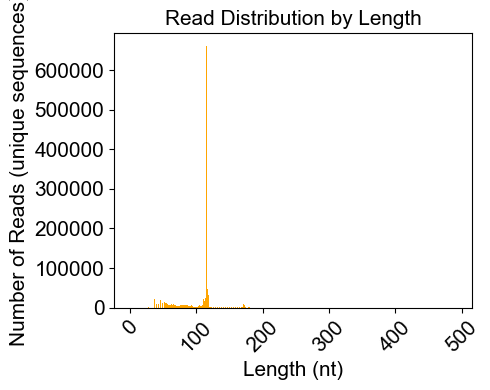

In [ ]:
#from matplotlib_venn import venn2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy as np
import pandas as pd
import os
#import seaborn as sns

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=15)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=9)


#labels = [f"Study{i}" for i in range(1, 16)]
#values = [243, 29, 12, 41, 9, 23, 6, 5, 36, 2, 113, 0, 11, 0, 9]
plt.figure(figsize=(5, 4))
print(x)
print(y)
plt.bar(x, y, color="orange")
#set y-axis limit
#plt.ylim(0, 746)

#labels and title with Arial
#plt.xlabel("Studies", fontproperties=arial_font)

#Count of unique sequences reported in paper each study
plt.xlabel("Length (nt)", fontproperties=arial_font)
plt.ylabel("Number of Reads (unique sequences)", fontproperties=arial_font)
plt.title("Read Distribution by Length", fontproperties=arial_font)

#apply Arial to ticks
plt.xticks(fontproperties=arial_font, rotation=45)

#plt.xticks([14, 25, 168, 317, 372, 745], ["15","26","169", "318", "373(50%)", "746"],fontproperties=arial_font, rotation=45)
plt.yticks(fontproperties=arial_font)
plt.tight_layout()
plt.show()
#plt.savefig("supp_figureX_E.pdf", format="pdf", bbox_inches="tight")

[15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231,

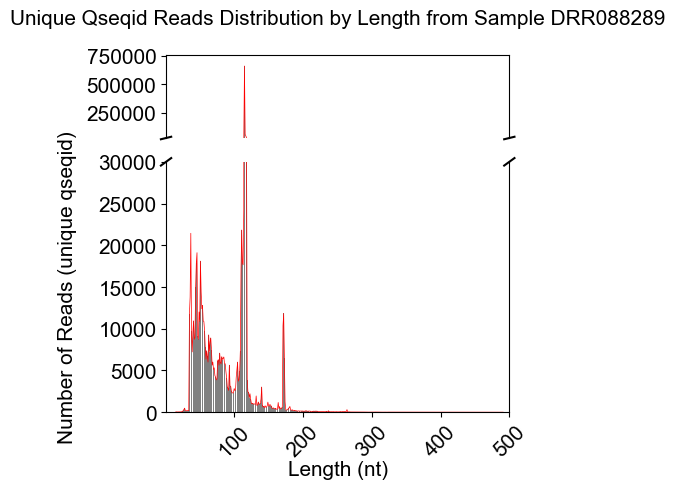

In [ ]:
#from matplotlib_venn import venn2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy as np
import pandas as pd
import os
#import seaborn as sns

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=15)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=9)
x_new = [xi for xi, yi in zip(x, y) if not (yi == 0)]
y_new = [yi for xi, yi in zip(x, y) if not (yi == 0)]
x = x_new
y = y_new
print(x)
print(y)
x_arr = np.array(x)
y_arr = np.array(y)
print(np.min(x_arr))
print(np.max(x_arr))
#Compute y-axis limits from data

y_max = int(np.max(y_arr))
#y_peak = y_arr[y_arr > 100].max()
y_peak = x_arr[y_arr > 30000].min()
x_start = x_arr.min()
print(y_peak)
print(x_start)
#y_sorted = np.sort(y_arr[y_arr > 0])[::-1]  #non-zero, descending


fig, (ax_top, ax_bottom) = plt.subplots(2, 1, sharex=True, figsize=(5, 5),
                                         gridspec_kw={'height_ratios': [1, 3]})

#Plot the same data on both axes
#ax_top.bar(x, y, color="gray")
#ax_bottom.bar(x, y, color="gray")
ax_top.bar(x, y, color="gray", linewidth=0.5)
ax_bottom.bar(x, y, color="gray", linewidth=0.5)
ax_top.plot(x, y, color="red", linewidth=0.5)
ax_bottom.plot(x, y, color="red", linewidth=0.5)
#ax_bottom.plot(x, y, color="orange", marker="o", markersize=0.1)

#Set y-axis ranges dynamically
ax_top.set_ylim(30000, y_max + 100000)         #upper broken part (around max)
ax_bottom.set_ylim(0, 30000)              #lower part (up to second highest + margin)

#Hide the spines between the two axes
ax_top.spines['bottom'].set_visible(False)
ax_bottom.spines['top'].set_visible(False)
ax_top.tick_params(bottom=False)

#Add diagonal break marks
d = 0.015
kwargs = dict(transform=ax_top.transAxes, color='k', clip_on=False)
ax_top.plot((-d, +d), (-d, +d), **kwargs)
ax_top.plot((1 - d, 1 + d), (-d, +d), **kwargs)

kwargs.update(transform=ax_bottom.transAxes)
ax_bottom.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax_bottom.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

#count of unique sequences reported in paper each study
#ax_top.set_ylabel("Number of Reads (unique qseqid)", fontproperties=arial_font)

ax_top.set_title("Unique Qseqid Reads Distribution by Length from Sample DRR088289", fontproperties=arial_font,pad=22)
#apply Arial to ticks
ax_bottom.tick_params(axis='x', rotation=45)
for ax in [ax_top, ax_bottom]:
    for label in ax.get_xticklabels():
        label.set_fontproperties(arial_font)
    for label in ax.get_yticklabels():
        label.set_fontproperties(arial_font)

#print(f"y_max={y_max}, y_second={y_second}")
ax_top.set_xlim(left=1, right=500)
ax_bottom.set_xlim(left=1, right=500)
ax_bottom.margins(x=0, y=0)


#ticks: y from 0, x from 1
#plt.xticks([15, 100, 200, 300, 400, 500], ["15","100", "200", "300", "400", "500"],fontproperties=arial_font, rotation=45)
plt.xlabel("Length (nt)", fontproperties=arial_font,labelpad=0)
plt.ylabel("Number of Reads (unique qseqid)", fontproperties=arial_font,labelpad=15)
#plt.yticks([5000,10000,15000,20000,25000,250000,660073,750000],["5000","10000","15000","20000","25000","250000","660073","750000"],fontproperties=arial_font)
plt.tight_layout()
#plt.show()
plt.savefig("fig3_1.pdf", format="pdf", bbox_inches="tight")

[15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 222, 223, 224, 225, 226, 227, 228, 229, 230, 231,

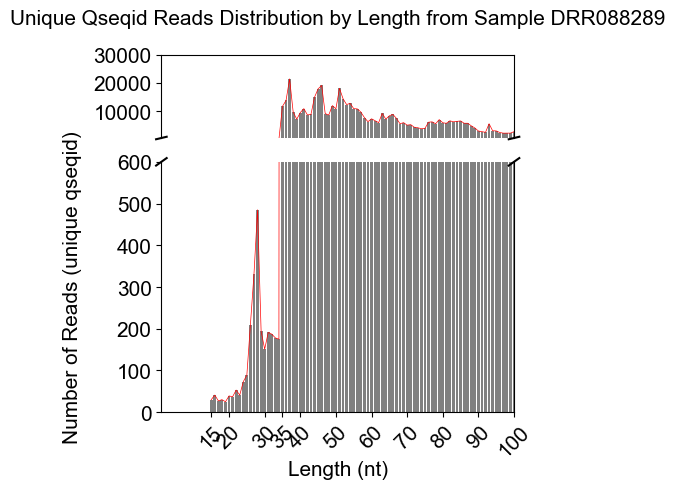

In [ ]:
#from matplotlib_venn import venn2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy as np
import pandas as pd
import os
#import seaborn as sns

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=15)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=9)
x_new = [xi for xi, yi in zip(x, y) if not (yi == 0)]
y_new = [yi for xi, yi in zip(x, y) if not (yi == 0)]
x = x_new
y = y_new
print(x)
print(y)
x_arr = np.array(x)
y_arr = np.array(y)
#print(np.min(x_arr))
#print(np.max(x_arr))
##Compute y-axis limits from data

#y_max = int(np.max(y_arr))
y_peak = x_arr[y_arr > 600].min()
y_second = y_arr[x_arr == 35]
#x_start = x_arr.min()
print(y_peak)
print(y_second)
#y_sorted = np.sort(y_arr[y_arr > 0])[::-1]  #non-zero, descending


fig, (ax_top, ax_bottom) = plt.subplots(2, 1, sharex=True, figsize=(5, 5),
                                         gridspec_kw={'height_ratios': [1, 3]})

#plot the same data on both axes
#ax_top.bar(x, y, color="gray")
#ax_bottom.bar(x, y, color="gray")
ax_top.bar(x, y, color="gray", linewidth=0.5)
ax_bottom.bar(x, y, color="gray", linewidth=0.5)
ax_top.plot(x, y, color="red", linewidth=0.5)
ax_bottom.plot(x, y, color="red", linewidth=0.5)
#ax_bottom.plot(x, y, color="orange", marker="o", markersize=0.1)

#set y-axis ranges dynamically
ax_top.set_ylim(600, 30000)         #upper broken part (around max)
ax_bottom.set_ylim(0, 600)              #lower part (up to second highest + margin)

#hide the spines between the two axes
ax_top.spines['bottom'].set_visible(False)
ax_bottom.spines['top'].set_visible(False)
ax_top.tick_params(bottom=False)

#add diagonal break marks
d = 0.015
kwargs = dict(transform=ax_top.transAxes, color='k', clip_on=False)
ax_top.plot((-d, +d), (-d, +d), **kwargs)
ax_top.plot((1 - d, 1 + d), (-d, +d), **kwargs)

kwargs.update(transform=ax_bottom.transAxes)
ax_bottom.plot((-d, +d), (1 - d, 1 + d), **kwargs)
ax_bottom.plot((1 - d, 1 + d), (1 - d, 1 + d), **kwargs)

ax_top.set_title("Unique Qseqid Reads Distribution by Length from Sample DRR088289", fontproperties=arial_font,pad=22)
#apply Arial to ticks
ax_bottom.tick_params(axis='x', rotation=45)
for ax in [ax_top, ax_bottom]:
    for label in ax.get_xticklabels():
        label.set_fontproperties(arial_font)
    for label in ax.get_yticklabels():
        label.set_fontproperties(arial_font)

#print(f"y_max={y_max}, y_second={y_second}")
ax_top.set_xlim(left=1, right=100)
ax_bottom.set_xlim(left=1, right=100)
ax_bottom.margins(x=0, y=0)


plt.xticks([15, 20, 30,35, 40, 50, 60, 70, 80, 90, 100], ["15", "20", "30","35", "40", "50", "60", "70", "80", "90", "100"],fontproperties=arial_font, rotation=45)

plt.xlabel("Length (nt)", fontproperties=arial_font,labelpad=0)
plt.ylabel("Number of Reads (unique qseqid)", fontproperties=arial_font,labelpad=25)
#plt.yticks([5000,10000,15000,20000,25000,250000,660073,750000],["5000","10000","15000","20000","25000","250000","660073","750000"],fontproperties=arial_font)
plt.tight_layout()
#plt.show()
plt.savefig("fig3_2.pdf", format="pdf", bbox_inches="tight")


In [ ]:
from Bio import SeqIO
from collections import Counter
import matplotlib.pyplot as plt
import os
import glob
import pandas as pd

def filter_fasta_by_txt(txt_file, fa_file):
    """
    1. Read a comma-delimited txt file, take unique values from the first column (numbers).
    2. Read a fasta file, find sequences whose header number > 1 among those unique numbers.
    3. Plot bar chart and line plot of sequence counts.
    Returns filtered sequences as a dict {name: sequence}.
    """
    #step 1: Read txt, get unique first-column values
    df = pd.read_csv(txt_file, header=None, sep=",")
    filtered_nums = set(df.iloc[:, 0].dropna().astype(int).unique())
    print("filtered_nums", filtered_nums)

    sequences = {}
    seen_seqs = set()

    for record in SeqIO.parse(fa_file, "fasta"):
        r_id = int(record.id)
        if r_id in filtered_nums:
            seq_str = str(record.seq)
            #Only add if this sequence hasn't been seen before
            if seq_str not in seen_seqs:
                sequences[r_id] = seq_str
                seen_seqs.add(seq_str)

    print(f"Filtered FASTA sequences: {len(sequences)}")

    #step 3: Count how many sequences have each length
    
    length_counts = Counter(len(seq) for seq in sequences.values())
    max_len = max(length_counts.keys())
    print("print max_len", max_len)
    x = list(range(1, max_len + 1))
    y = [length_counts.get(l, 0) for l in x]
    return x, y

x,y = filter_fasta_by_txt("16th_new_paper_29211829_results/original_100_100_mapping_results/map_genome/blast_score_filter.txt", "16th_new_paper_29211829_results/original_100_100_mapping_results/final_seq_12.fasta")

filtered_nums {7, 17, 23, 24, 25, 26, 27, 29, 31, 32, 35, 37, 38, 41, 42, 43, 44, 45, 46, 47, 52, 55, 56, 63, 64, 65, 66, 69, 70, 71, 72, 73, 74, 75, 77, 78, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 94, 95, 96, 97, 98, 99, 100, 101, 103, 106, 107, 109, 111, 114, 117, 118, 119, 120, 121, 123, 125, 126, 127, 129, 133, 135, 137, 138, 141, 144, 145, 147, 150, 152, 153, 154, 155, 156, 157, 159, 162, 163, 164, 165, 166, 167, 169, 171, 172, 174, 175, 176, 177, 179, 181, 182, 184, 186, 188, 189, 192, 193, 195, 197, 198, 199, 200, 201, 205, 206, 208, 209, 210, 211, 214, 216, 219, 220, 221, 223, 225, 229, 230, 231, 233, 234, 235, 237, 239, 242, 243, 245, 246, 248, 249, 252, 253, 254, 256, 259, 260, 262, 263, 264, 265, 266, 268, 269, 270, 272, 274, 277, 278, 280, 283, 284, 285, 286, 288, 291, 294, 295, 296, 298, 299, 300, 301, 305, 307, 308, 309, 310, 311, 315, 316, 317, 320, 321, 322, 323, 324, 325, 326, 327, 328, 329, 330, 331, 333, 335, 337, 338, 339, 343, 344, 346, 350, 352, 353, 354, 

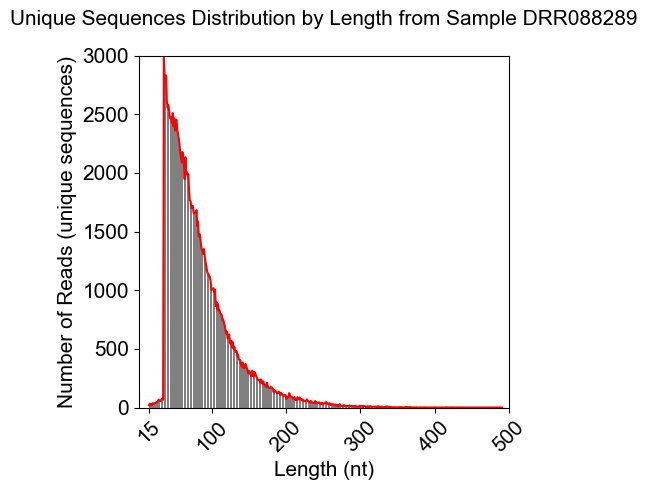

In [ ]:
#from matplotlib_venn import venn2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy as np
import pandas as pd
import os
#import seaborn as sns

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=15)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=9)


#labels = [f"Study{i}" for i in range(1, 16)]
#values = [243, 29, 12, 41, 9, 23, 6, 5, 36, 2, 113, 0, 11, 0, 9]
plt.figure(figsize=(5,5))
#print(x)
#print(y)
#x_arr = np.array(x)
#print(np.min(x_arr))
#print(np.max(x_arr))
x_new = [xi for xi, yi in zip(x, y) if not (yi == 0)]
y_new = [yi for xi, yi in zip(x, y) if not (yi == 0)]
x = x_new
y = y_new
plt.plot(x, y, color="red")
plt.bar(x, y, color="gray")


plt.xlim(left=1, right=500)
plt.ylim(0,3000)
plt.margins(x=0, y=0)
#count of unique sequences reported in paper each study
plt.xlabel("Length (nt)", fontproperties=arial_font)
plt.ylabel("Number of Reads (unique sequences)", fontproperties=arial_font)
plt.title("Unique Sequences Distribution by Length from Sample DRR088289", fontproperties=arial_font, pad=22)

#apply Arial to ticks
plt.xticks([15,  100, 200, 300, 400, 500], ["15",  "100","200", "300", "400", "500"],fontproperties=arial_font, rotation=45)


#plt.xticks([14, 25, 168, 317, 372, 745], ["15","26","169", "318", "373(50%)", "746"],fontproperties=arial_font, rotation=45)
plt.yticks(fontproperties=arial_font)

plt.tight_layout()
#plt.show()
plt.savefig("fig4_1.pdf", format="pdf", bbox_inches="tight")

35
2980
15


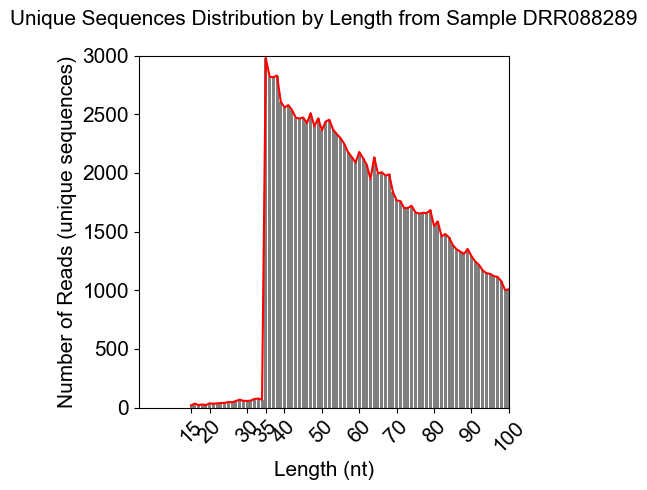

In [ ]:
#from matplotlib_venn import venn2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy as np
import pandas as pd
import os
#import seaborn as sns

fm.fontManager.addfont(str("arial.ttf"))

arial_font = fm.FontProperties(fname="arial.ttf", size=15)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=9)


#labels = [f"Study{i}" for i in range(1, 16)]
#values = [243, 29, 12, 41, 9, 23, 6, 5, 36, 2, 113, 0, 11, 0, 9]
plt.figure(figsize=(5,5))
#print(x)
#print(y)
#x_arr = np.array(x)
#print(np.min(x_arr))
#print(np.max(x_arr))
x_new = [xi for xi, yi in zip(x, y) if not (yi == 0)]
y_new = [yi for xi, yi in zip(x, y) if not (yi == 0)]
x = x_new
y = y_new
plt.plot(x, y, color="red")
plt.bar(x, y, color="gray")

x_arr = np.array(x)
y_arr = np.array(y)

y_peak = y_arr[x_arr < 100].max()
x_peak = x_arr[y_arr == 2980].min()
x_start = x_arr.min()
print(x_peak)
print(y_peak)
print(x_start)

plt.xlim(left=1, right=100)
plt.ylim(0,3000)
plt.margins(x=0, y=0)
#count of unique sequences reported in paper each study
plt.xlabel("Length (nt)", fontproperties=arial_font)
plt.ylabel("Number of Reads (unique sequences)", fontproperties=arial_font)
plt.title("Unique Sequences Distribution by Length from Sample DRR088289", fontproperties=arial_font,pad=22)

#apply Arial to ticks
plt.xticks([15, 20, 30,35, 40, 50, 60, 70, 80, 90, 100], ["15", "20", "30","35", "40", "50", "60", "70", "80", "90", "100"],fontproperties=arial_font, rotation=45)


#plt.xticks([14, 25, 168, 317, 372, 745], ["15","26","169", "318", "373(50%)", "746"],fontproperties=arial_font, rotation=45)
plt.yticks(fontproperties=arial_font)

plt.tight_layout()
#plt.show()
plt.savefig("fig4_2.pdf", format="pdf", bbox_inches="tight")